In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import config as c
import numpy as np

In [2]:
sns.set_context("notebook")
sns.set_style("whitegrid")
sns.set_theme(

    rc={"font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],

        "axes.labelsize": 13,
        "axes.titlesize": 15,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "legend.fontsize": 11,
        "legend.title_fontsize": 12,

        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 1.0})

Let's process already cleaned and fully preprocessed (continous signal processing + windowed signal processing) exams. In exams_processed.csv there are only "ok" recordings, to proceed with in trainings.

## upload metadata & have a first look

In [3]:
filepath = f"{c.META_DIR}/exams_processed.csv"
df = pd.read_csv(filepath, encoding = 'utf-8')
df.head()

,site,patient_id,exam_id,age,age_group,female,pathology
0,S00,P27809,20220512-164523-{3222752a-e1a1-439f-b7a7-85642...,56.9,56-65,0,0
1,S00,P27811,20220512-164615-{ee327e54-0056-41d9-84a4-a4243...,31.2,26-35,0,0
2,S00,P27812,20220512-164352-{310806e9-34f6-4c9e-9478-1726b...,31.2,26-35,0,0
3,S00,P27818,20220512-164324-{d7f16f2a-5bb3-47e8-80fc-76fa5...,40.2,36-45,1,0
4,S00,P27819,20220512-164255-{8efca8a5-c0f8-4ceb-b0b4-e3ade...,39.2,36-45,1,0


In [4]:
df.shape

(34831, 7)

The shape is the same as memmap, so it's good.

In [5]:
new_filename_1 = f'{c.META_DIR}/sites_processed.csv'
new_filename_2 = f'{c.META_DIR}/longitudinal_processed.csv'

In [6]:
LABEL_PALETTE = {'0': "#4A90E2", '1': "#E06666"}
SEX_PALETTE = {'0': "#00A878", '1': "#9B51E0"}

bins = [0, 1]
label_labels = ['Norm', 'Pathology']
sex_labels = ['Male', 'Female']

SITE_ORDER = ['S00', 'S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09',
       'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'S19',
       'S21', 'S22', 'S23', 'S24', 'S25', 'S26', 'S28', 'S29']


In [7]:
N_exams_original = df.shape[0]
N_prior = 46615

/tmp/ipykernel_2502570/2834921473.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.catplot(x = 'pathology',


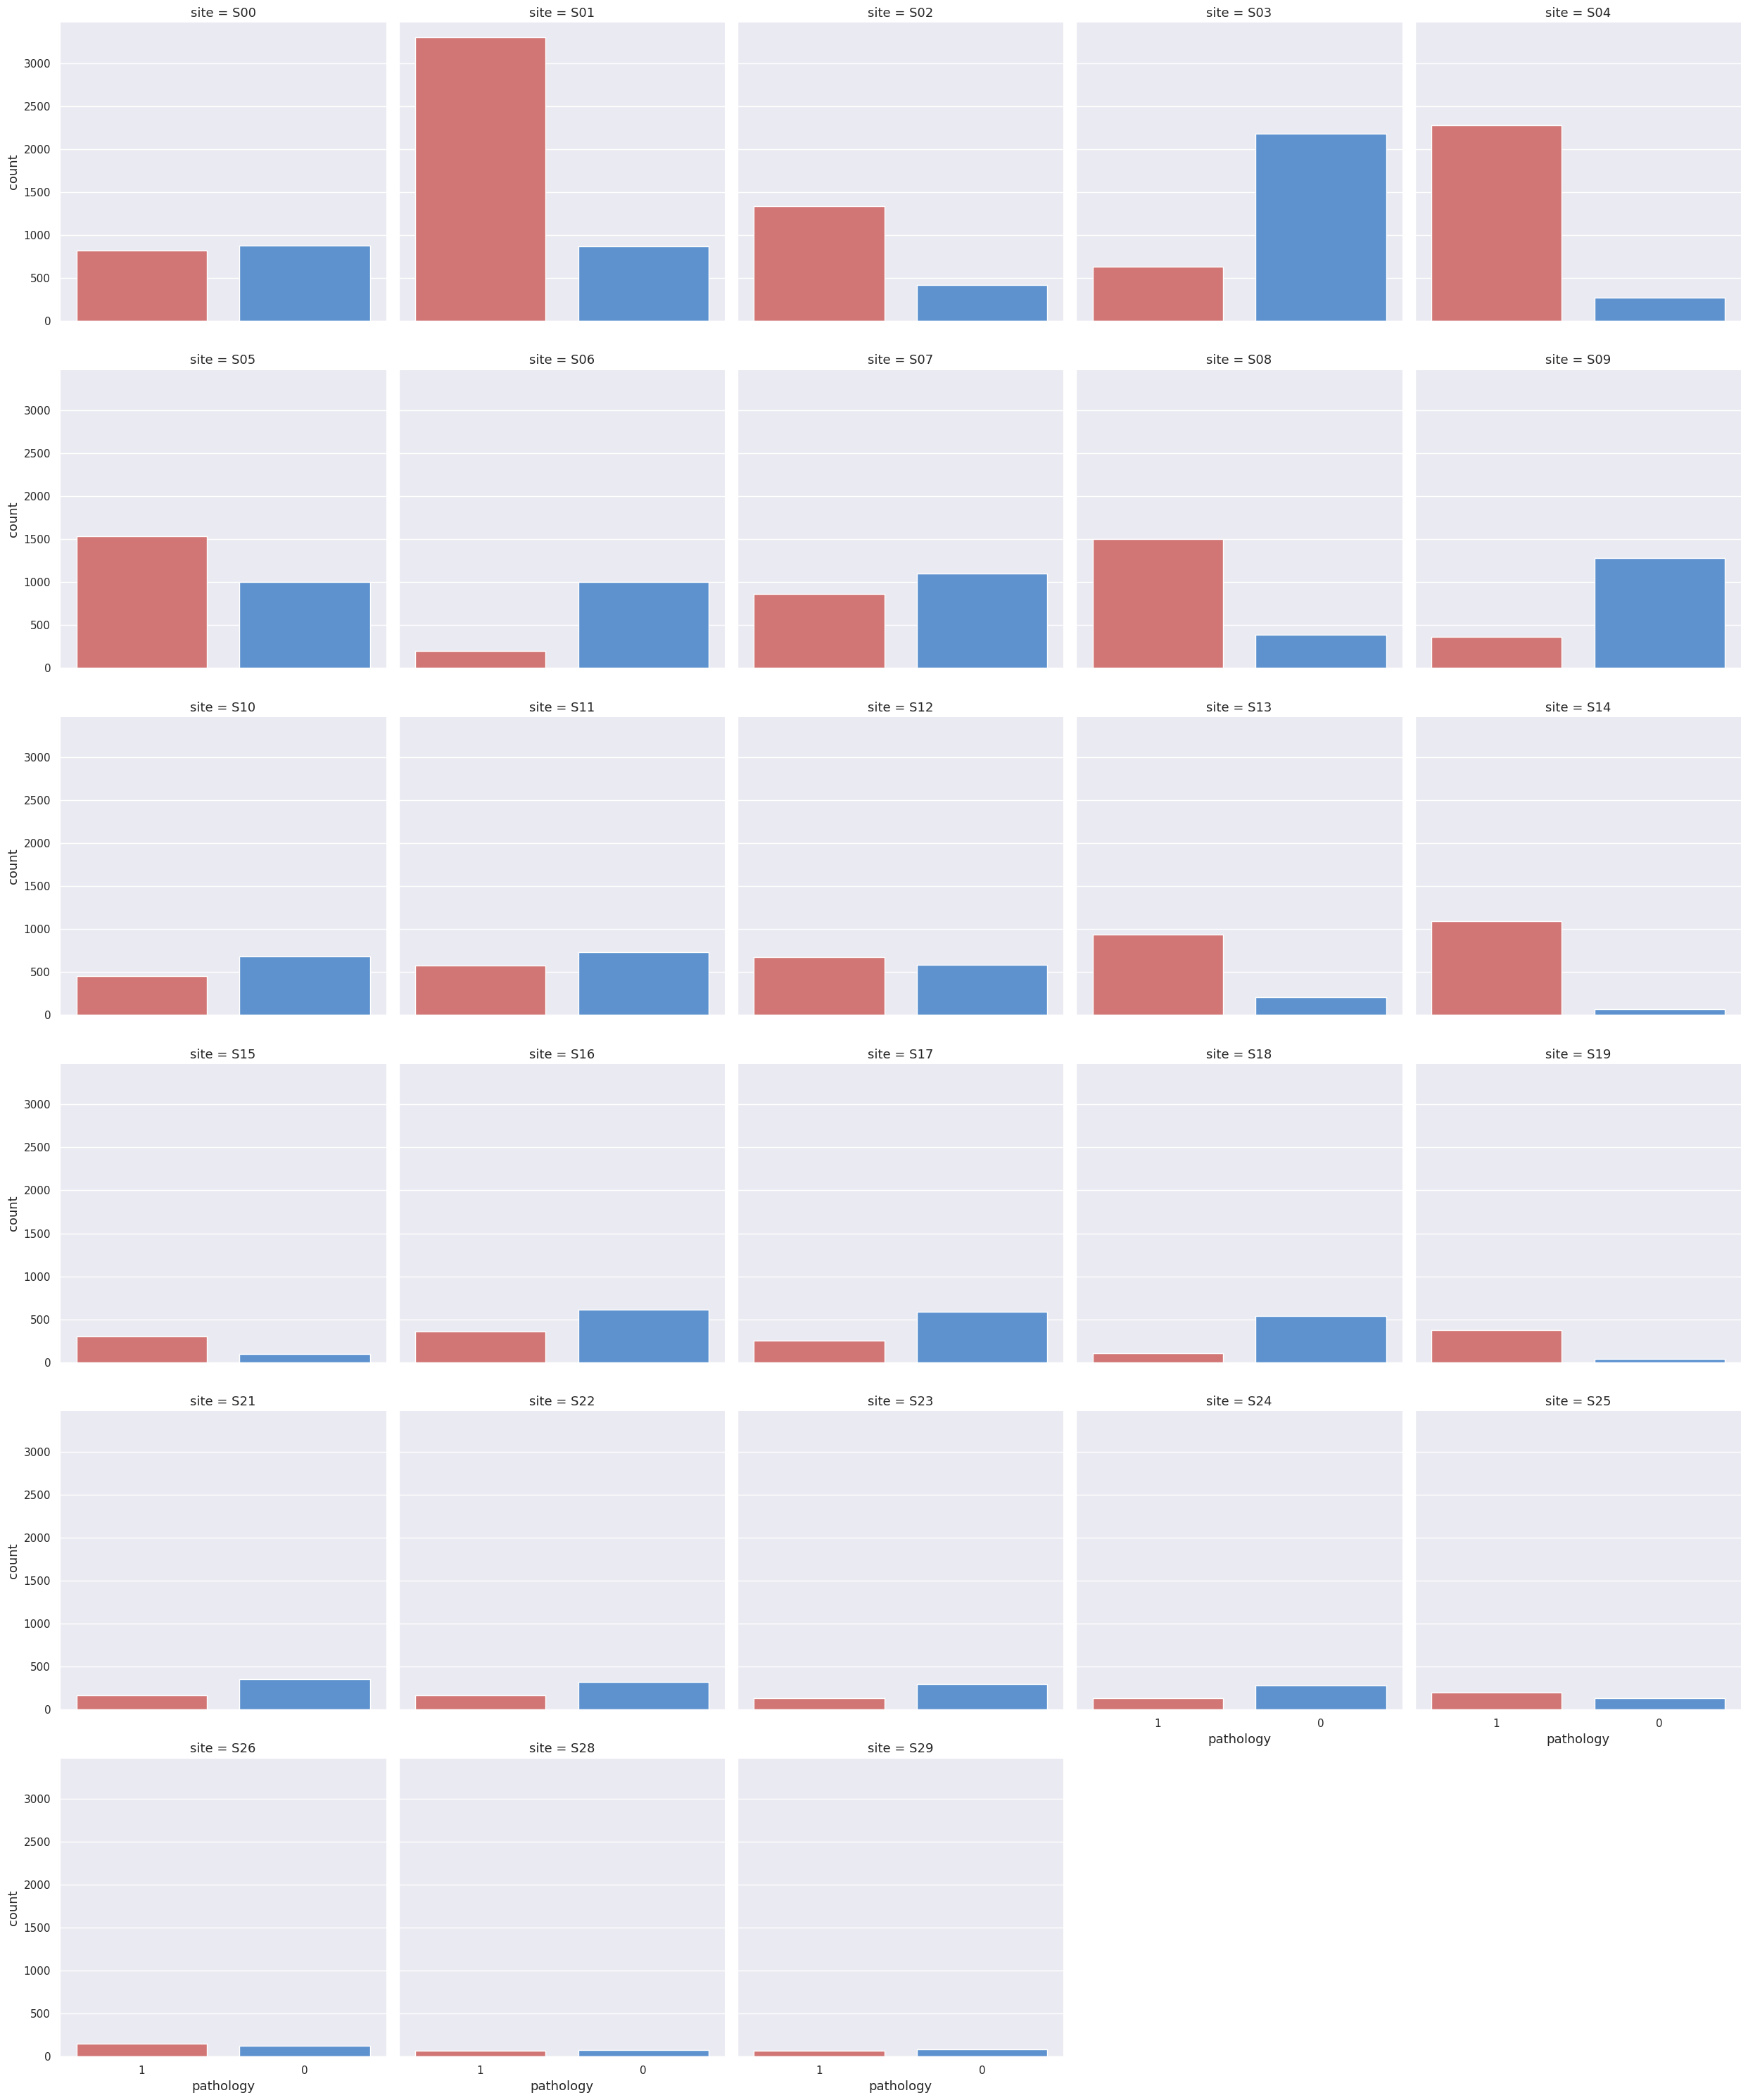

In [8]:
sns.catplot(x = 'pathology',
            data = df,
            col = 'site',
            col_wrap = 5,
            kind = 'count',
            order = [1,0],
            palette = LABEL_PALETTE,
            col_order = SITE_ORDER)

All recordings from S20 & S27 have been removed during DSP.

In [9]:
df.isnull().any()

site          False
patient_id    False
exam_id       False
age           False
age_group     False
female        False
pathology     False
dtype: bool

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34831 entries, 0 to 34830
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   site        34831 non-null  object 
 1   patient_id  34831 non-null  object 
 2   exam_id     34831 non-null  object 
 3   age         34831 non-null  float64
 4   age_group   34831 non-null  object 
 5   female      34831 non-null  int64  
 6   pathology   34831 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 1.9+ MB


In [33]:
duplicate_exam_ids = df['exam_id'].duplicated().sum()
duplicate_subject_exam_pairs = df.duplicated(subset=['patient_id', 'exam_id']).sum()

print(f"Duplicate examination IDs: {duplicate_exam_ids}")
print(f"Duplicate subject/examination pairs: {duplicate_subject_exam_pairs}")

Duplicate examination IDs: 0
Duplicate subject/examination pairs: 0


In [12]:
print(f"There are {N_exams_original} in the final dataset. Preprocessing-only discarded {N_prior - N_exams_original} exams, which is {np.round((N_prior-N_exams_original)/N_prior, 2)*100}%.")

There are 34831 in the final dataset. Preprocessing-only discarded 11784 exams, which is 25.0%.


## descriptive statistics 

In [13]:
df_structure_global = pd.DataFrame({'Metric': [ '# exams', '# unique patients',
                                                '# longitudinal patients'],
                                    'Value': [  len(df), df['patient_id'].nunique(),
                                                df['patient_id'].value_counts().gt(1).sum()]})
df_structure_global.style.hide(axis='index')

Metric,Value
# exams,34831
# unique patients,30617
# longitudinal patients,2883


In [15]:
label_counts = df['pathology'].value_counts()
target_ratio = label_counts[1] / (label_counts[0] + label_counts[1])
relation = label_counts[1] / label_counts[0]

print("Target count: ", label_counts[1])
print("Target ratio (pathology/all labels):", (target_ratio* 100).round(2) , '%') #type:ignore
print("Pathology : norm relation:", relation.round(2)) #type:ignore

Target count:  19305
Target ratio (pathology/all labels): 55.42 %
Pathology : norm relation: 1.24


Target class is overrepresented, but in global perspective it is not a huge imbalance.

In [16]:
sex_count = df['female'].value_counts()
female_ratio = sex_count[1] / (sex_count[0] + sex_count[1])
sex_relation = sex_count[1] / sex_count[0]

print("Female count: ", sex_count[1] )
print("Female ratio (female/all subjects):", female_ratio.round(2)*100, '%') #type:ignore   
print("Female : male relation:", sex_relation.round(1)) #type:ignore

Female count:  18278
Female ratio (female/all subjects): 52.0 %
Female : male relation: 1.1


In [17]:
age_group_counts = df['age_group'].value_counts().sort_index()
AGE_ORDER = []
print('Sorted age group distribution :')
for age_group, count in age_group_counts.sort_values(ascending=False).items():
    print(f"Age group {age_group}: {count} ({(count / len(df) * 100):.2f}%)")  # type: ignore
    AGE_ORDER.append(age_group)

Sorted age group distribution :
Age group 16-25: 8923 (25.62%)
Age group 26-35: 7127 (20.46%)
Age group 36-45: 6365 (18.27%)
Age group 56-65: 6216 (17.85%)
Age group 46-55: 6200 (17.80%)


In [18]:
AGE_ORDER

['16-25', '26-35', '36-45', '56-65', '46-55']

In [19]:
df['age'].describe()

count    34831.000000
mean        38.837722
std         14.819728
min         16.000000
25%         25.600000
50%         38.000000
75%         52.200000
max         65.000000
Name: age, dtype: float64

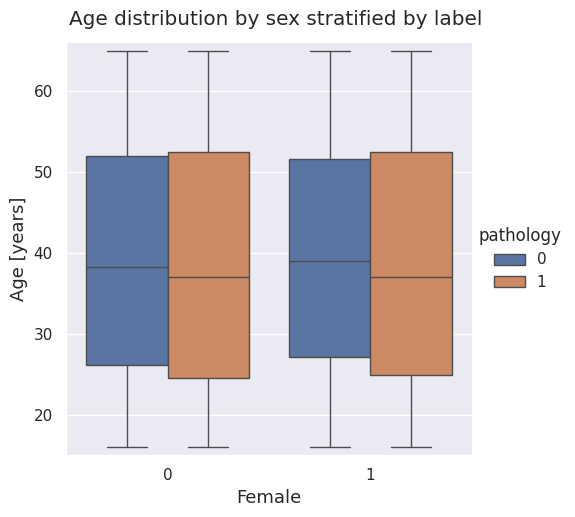

In [20]:
g = sns.catplot(
    x="female",
    y="age",
    data=df,
    hue="pathology",
    kind="box"
)

g.figure.suptitle(t = "Age distribution by sex stratified by label", y = 1.03)
g.set(
    xlabel="Female",
    ylabel="Age [years]",
    ylim=(15, 66)
)

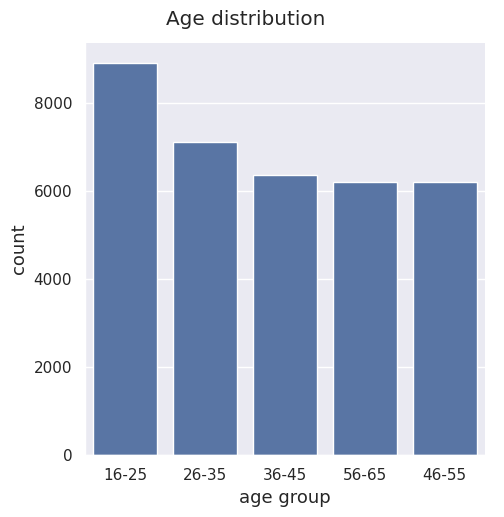

In [21]:
# age distribution (in bins of 10 years)
g = sns.catplot(x='age_group',
                data = df,
                kind = 'count',
                order=AGE_ORDER)

g.figure.suptitle('Age distribution', y = 1.03)
g.set(xlabel = 'age group')


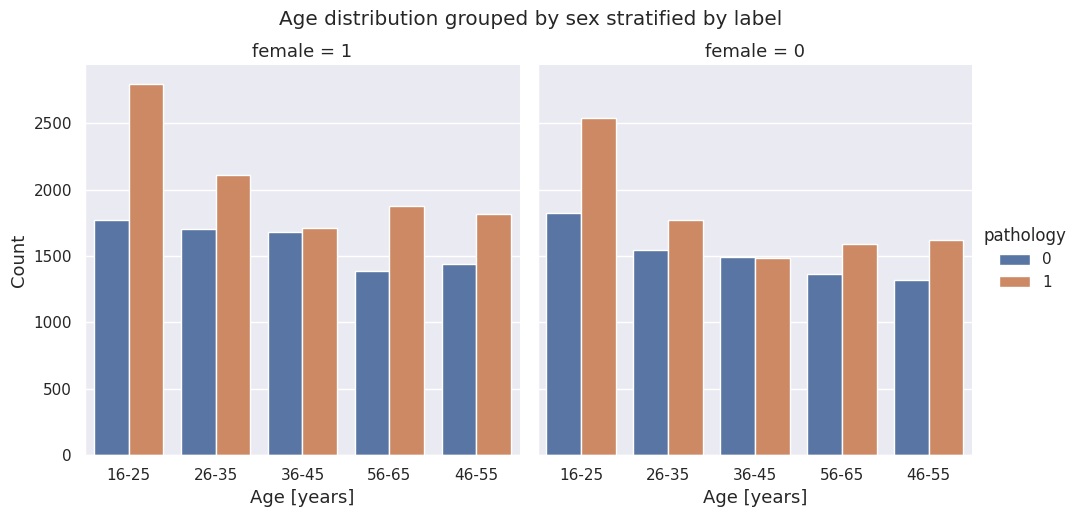

In [22]:
g = sns.catplot(x='age_group',
                data = df,
                hue = 'pathology',
                kind = 'count',
                col = "female",
                order = AGE_ORDER,
                col_order= [1,0])

g.figure.suptitle('Age distribution grouped by sex stratified by label', y = 1.03)
g.set(xlabel = 'Age [years]', ylabel = 'Count')

/tmp/ipykernel_2502570/2804642777.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g = sns.catplot(x='pathology',


Text(0.5, 1.03, 'Label distribution per sex')

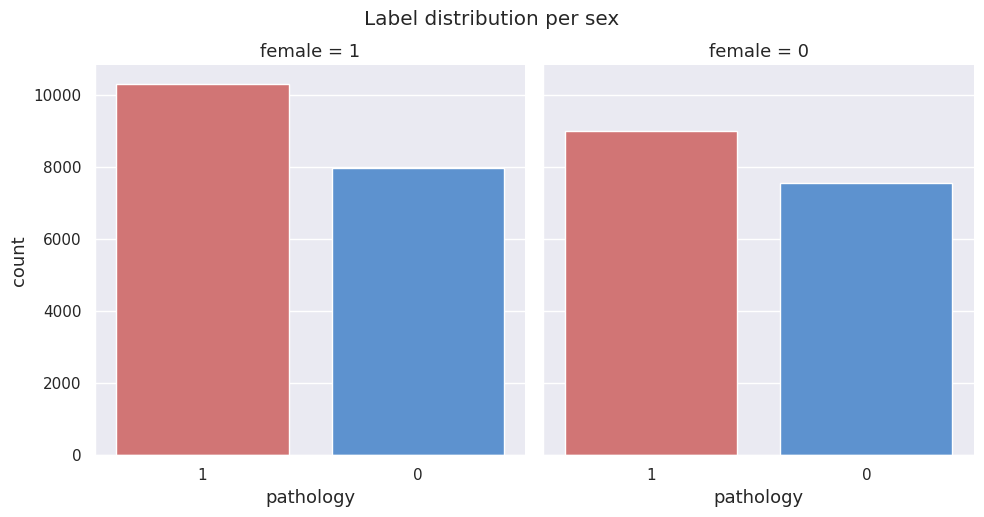

In [23]:
g = sns.catplot(x='pathology', 
            data = df,
            kind = 'count',
            order = [1, 0],
            col = "female",
            col_order = [1,0],
            palette = LABEL_PALETTE)

g.figure.suptitle('Label distribution per sex', y = 1.03)

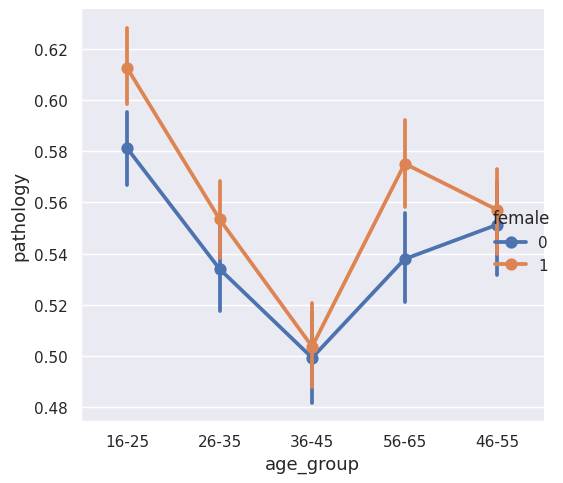

In [24]:
sns.catplot(x = "age_group",
            y = "pathology",
            data = df,
            kind = "point",
            hue = "female",
            order = AGE_ORDER,
            legend_out=True)

plt.tight_layout()

## per site

In [25]:
sites_data = pd.DataFrame({
    'site': SITE_ORDER,
    '#exams': df['site'].value_counts().loc[SITE_ORDER].values,
    '#unique_subs': df.groupby('site')['patient_id'].nunique().loc[SITE_ORDER].values,
    '#unique_long_subs': df.groupby('site')['patient_id'].value_counts().gt(1).groupby('site').sum().loc[SITE_ORDER].values})

sites_data.style.hide(axis='index')

site,#exams,#unique_subs,#unique_long_subs
S00,1697,1539,111
S01,4172,3594,412
S02,1750,1431,212
S03,2806,2384,272
S04,2545,2464,51
S05,2526,2085,305
S06,1198,1036,110
S07,1958,1909,45
S08,1888,1439,268
S09,1641,1487,96


In [26]:
temp_df = pd.merge(df, sites_data, on=['site'], how='inner')
longitudinal_data = (
    temp_df
    .groupby(['site', 'patient_id'])
    .size()
    .loc[lambda x: x > 1]
    .reset_index(name='n_exams')
)

In [27]:
longitudinal_data

,site,patient_id,n_exams
0,S00,P00006,4
1,S00,P02352,2
2,S00,P02392,2
3,S00,P02737,3
4,S00,P02741,3
...,...,...,...
2837,S29,P15948,2
2838,S29,P15955,2
2839,S29,P22282,2
2840,S29,P28635,2


In [28]:
N_longs = len(longitudinal_data["site"].unique())

In [31]:
print("Number of sites with longitudinal patients:", N_longs)
print("Sites without longitudinal patients are:", set(df['site'].unique()) - set(longitudinal_data["site"].unique()) - set(['S20', 'S27']))

Number of sites with longitudinal patients: 26
Sites without longitudinal patients are: {'S15', 'S19'}


In [32]:
sites_data.to_csv(new_filename_1, index=False)
longitudinal_data.to_csv(new_filename_2, index=False)

print(f"Saved site metadata to: {new_filename_1}")
print(f"Saved longitudinal patients metadata to: {new_filename_2}")

Saved site metadata to: /dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/data/meta/sites_processed.csv
Saved longitudinal patients metadata to: /dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/data/meta/longitudinal_processed.csv
